# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [3]:
ROLL_NO = 1024170300# <-- your full roll number
NAME = "Sukhriti Kaur Bhangu"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170300   Name: Sukhriti Kaur Bhangu   Fingerprint: C7A7FC2D   Tickets: 12

Ticket_ID                                                                                  Ticket_Text
      T01                            I was locked out of the projector during the lab. This is urgent.
      T02           Matlab keeps asking for login when connected to campus Wi-Fi. It worked yesterday.
      T03 Python keeps asking for login when connected to campus Wi-Fi. The same problem occurs again.
      T04                 I keep getting logged out of the Matlab during the lab. It worked yesterday.
      T05                                                  The state-of-the-art lab (Lab-3) is closed.
      T06                 I can't open the WiFi after the latest update. It works on another computer.
      T07           I tried restarting the student portal before the assignment deadline. Please help.
      T08                                                  I can't login and I didn'

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
# Your code

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []

for i, result in enumerate(processed):
    rows.append({
        "Ticket_ID": df.iloc[i]["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary["Sentences"].sum(),
    "Tokens": summary["Tokens"].sum(),
    "Punctuation Tokens": summary["Punctuation Tokens"].sum(),
    "Stopwords": summary["Stopwords"].sum(),
    "Unique Tokens": len(set(
        token for result in processed for token in result["tokens"]
    )),
    "Final Tokens": summary["Final Tokens"].sum()
}

summary = pd.concat(
    [summary, pd.DataFrame([total_row])],
    ignore_index=True
)

print(summary.to_string(index=False))

focus_id = FOCUS[0]
idx = df.index[df["Ticket_ID"] == focus_id][0]
result = processed[idx]

print("\nSelected Ticket:", focus_id)
print("Raw text:", df.loc[idx, "Ticket_Text"])
print("Actual tokens:", result["tokens"])
print("Punctuation tokens:", result["punct"])
print("Stopwords:", result["stops"])
print("Final tokens:", result["final"])


Ticket_ID  Sentences  Tokens  Punctuation Tokens  Stopwords  Unique Tokens  Final Tokens
      T01          2      15                   2          9             13             4
      T02          2      15                   2          4             14             9
      T03          2      17                   2          6             16             9
      T04          2      16                   2          7             14             7
      T05          1       9                   3          2              9             4
      T06          2      17                   2          6             15             9
      T07          2      14                   2          4             12             8
      T08          1      11                   1          4              9             6
      T09          2      13                   2          5             13             6
      T10          1       6                   1          1              6             4
      T11          2 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

Your answer:
Some final tokens, such as ca and n't, are not complete words. They come from contractions in the original tickets. For example, can't is split into ca and n't, and didn't is split into did and n't. The word_tokenize() function performs this splitting. Since the preprocessing pipeline removes stopwords and punctuation but does not join contraction fragments, these tokens may remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

raw_text = "\n".join(df["Ticket_Text"])

# Extract words longer than 5 letters
long_words = re.findall(r"\b[A-Za-z]{6,}\b", raw_text)

# Extract integers, decimals and versions such as 2.0.1
numbers = re.findall(r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|\b\d+\b", raw_text)

# Extract capitalized words
capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", raw_text)

# Extract words beginning with a vowel
vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", raw_text)

print("Words longer than 5 letters:\n", long_words)
print("\nNumbers:\n", numbers)
print("\nCapitalized words:\n", capitalized_words)
print("\nWords beginning with a vowel:\n", vowel_words)

# Replacement patterns
email_pattern = r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b"
url_pattern = r"""(?:https?://|www\.)[^\s<>"']*[^\s<>"'.,!?;:]"""
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{3,5}(?:[\s-]\d{3,5}){1,2})(?!\w)"

def replace_patterns(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nReplacements on TEST_LINES:")
for line in TEST_LINES:
    print(replace_patterns(line))

print("\nReplacements on generated tickets:")
for ticket in df["Ticket_Text"]:
    print(replace_patterns(ticket))

# Count capitalized words at sentence beginnings
sentence_start_words = []

for ticket in df["Ticket_Text"]:
    for sentence in sent_tokenize(ticket):
        match = re.match(r"\s*([A-Za-z]+)", sentence)
        if match and match.group(1)[0].isupper():
            sentence_start_words.append(match.group(1))

print("\nCapitalized sentence-start words:", sentence_start_words)
print("Number of sentence-start capitalized occurrences:", len(sentence_start_words))


Words longer than 5 letters:
 ['locked', 'projector', 'during', 'urgent', 'Matlab', 'asking', 'connected', 'campus', 'worked', 'yesterday', 'Python', 'asking', 'connected', 'campus', 'problem', 'occurs', 'getting', 'logged', 'Matlab', 'during', 'worked', 'yesterday', 'closed', 'latest', 'update', 'another', 'computer', 'restarting', 'student', 'portal', 'before', 'assignment', 'deadline', 'Please', 'change', 'anything', 'MATLAB', 'disconnecting', 'restarting', 'system', 'Python', 'installed', 'yesterday', 'unable', 'Python', 'laptop', 'urgent', 'helpdesk', 'thapar', 'thapar']

Numbers:
 ['3', '3.12']

Capitalized words:
 ['I', 'This', 'Matlab', 'Wi', 'Fi', 'It', 'Python', 'Wi', 'Fi', 'The', 'I', 'Matlab', 'It', 'The', 'Lab', 'I', 'WiFi', 'It', 'I', 'Please', 'I', 'I', 'MATLAB', 'Can', 'Python', 'I', 'Python', 'This', 'Write']

Words beginning with a vowel:
 ['I', 'out', 'of', 'is', 'urgent', 'asking', 'It', 'asking', 'occurs', 'again', 'I', 'out', 'of', 'It', 'of', 'art', 'is', 'I', 'o

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
The output contains 20 capitalized sentence-start word occurrences. Some examples are I, This, It, The, and Please. However, not every capitalized word is capitalized only because it begins a sentence. Terms such as MATLAB, WiFi, and Lab can be capitalized because they are names or identifiers. Therefore, sentence position should be considered when interpreting the capitalized-word extraction results.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = r"""(?ix)
    (?:https?://|www\.)[^\s<>"']*[^\s<>"'.,!?;:]
    |
    [A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9-]+(?:\.[A-Z0-9-]+)+
    |
    (?<!\w)(?:\+\d{1,3}[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{3,5}(?:[\s-]\d{3,5}){1,2})(?!\w)
    |
    \b\d+(?:\.\d+)+\b
    |
    \b[A-Z]+(?:-[A-Z]+)+\b
    |
    \b[A-Z]+(?:'[A-Z]+)+\b
    |
    [A-Z]+
    |
    [^\w\s]
"""

custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("TOKENIZATION OF TEST_LINES")

for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("NLTK:", word_tokenize(line))

print("\nTOKENIZATION OF GENERATED TICKETS")

different_tickets = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    print("\n", row["Ticket_ID"])
    print("Custom:", custom)
    print("NLTK:", standard)

    if custom != standard:
        different_tickets.append(row["Ticket_ID"])

print("\nNumber of tickets tokenized differently:", len(different_tickets))
print("Ticket IDs:", different_tickets)


TOKENIZATION OF TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
Four tickets (T05, T06, T08, and T12) were tokenized differently. Differences occurred because of hyphenated words, contractions, and Markdown-formatted email addresses and URLs.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
# Your code

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$", min=5)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

unique_final = sorted(set(
    token for result in processed for token in result["final"]
))

pos_tags = dict(nltk.pos_tag(unique_final))

stem_rows = []

for word in unique_final:
    tag = pos_tags[word]
    pos = get_wordnet_pos(tag)

    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    if len({p, l, r, lemma}) > 1:
        stem_rows.append({
            "Word": word,
            "POS": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

stem_table = pd.DataFrame(stem_rows)

print("Regexp suffix selected: ing$")
print("Dataset words ending in 'ing':",
      [w for w in unique_final if w.endswith("ing")])

print("\nWords with differing outputs:")
print(stem_table.to_string(index=False) if not stem_table.empty
      else "No differing outputs found.")


Regexp suffix selected: ing$
Dataset words ending in 'ing': ['anything', 'asking', 'disconnecting', 'getting', 'restarting']

Words with differing outputs:
      Word POS    Porter Lancaster     Regexp WordNet Lemma
   another  DT     anoth     anoth    another       another
  anything  NN     anyth     anyth      anyth      anything
assignment  NN    assign    assign assignment    assignment
    campus  VB     campu      camp     campus        campus
    change  NN     chang     chang     change        change
    closed VBD     close      clos     closed         close
  computer  NN    comput    comput   computer      computer
 connected VBN   connect   connect  connected       connect
  deadline  NN   deadlin   deadlin   deadline      deadline
   getting VBG       get       get       gett           get
 installed  VB    instal    instal  installed        instal
     keeps NNS      keep      keep      keeps          keep
    latest JJS    latest    latest     latest          late
    

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
Over-stemming removes too much of a word, producing an incorrect stem, while under-stemming fails to reduce related words to the same stem. The examples should be selected from the generated comparison table.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus statistics:
    Total Tokens  Unique Tokens     TTR
S1         157.0           83.0  0.5287
S2         134.0           78.0  0.5821
S3          76.0           54.0  0.7105
S4          76.0           52.0  0.6842

Top 10 words in S1:
[('.', 19), ('the', 12), ('i', 7), ('to', 4), ('lab', 3), ('this', 3), ('is', 3), ('matlab', 3), ('keeps', 3), ('login', 3)]

Top 10 words in S3:
[('lab', 3), ('matlab', 3), ('keeps', 3), ('login', 3), ('yesterday', 3), ('python', 3), ("n't", 3), ('urgent', 2), ('asking', 2), ('connected', 2)]


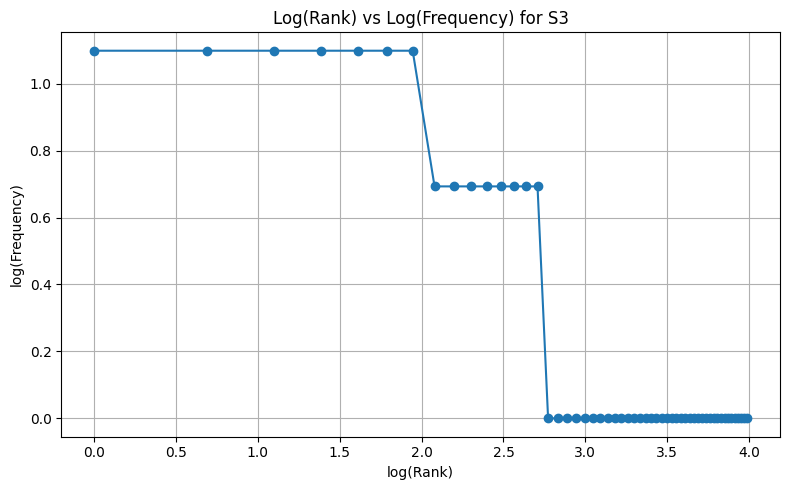


Top 5 bigrams in S1:
[(('.', 'i'), 5), (('.', 'it'), 3), (('yesterday', '.'), 3), (('out', 'of'), 2), (('of', 'the'), 2)]

Top 5 bigrams in S3:
[(('matlab', 'keeps'), 2), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('login', 'connected'), 2), (('connected', 'campus'), 2)]


In [11]:
# Your code

import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams

# S1: All tokens
S1 = [t for result in processed for t in result["tokens"]]

# S2: Tokens without punctuation
S2 = [t for t in S1 if not is_punct(t)]

# S3: Final tokens
S3 = [t for result in processed for t in result["final"]]

# S4: Porter-stemmed final tokens
S4 = [porter.stem(t) for t in S3]

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame({
    "S1": corpus_stats(S1),
    "S2": corpus_stats(S2),
    "S3": corpus_stats(S3),
    "S4": corpus_stats(S4)
}).T

print("Corpus statistics:")
print(stats.to_string())

print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) versus log(frequency) for S3
freq = Counter(S3)
ranked = freq.most_common()

ranks = list(range(1, len(ranked) + 1))
frequencies = [count for word, count in ranked]

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(r) for r in ranks],
    [math.log(f) for f in frequencies],
    marker="o"
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
TTR increases from S1 (0.5287) to S3 (0.7105) because removing punctuation and stopwords reduces repeated tokens. It then decreases to 0.6842 in S4 because stemming reduces unique tokens from 54 to 52.